# Testes de especificação --- prática

**Curso de Econometria Espacial**  
Prof. Pedro Amaral · Cedeplar/UFMG  

Dados: *chicagoSDOH* (`Chi-SDOH.shp`) via `libpysal.examples`.


## 1. Importações

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns

import libpysal
import spreg

## 2. Dados: chicagoSDOH

In [2]:
# Carrega o exemplo e lista os arquivos
sdoh = libpysal.examples.load_example('chicagoSDOH')
sdoh.get_file_list()

['/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/Chi-SDOH.prj',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/Chi-SDOH_q.gal',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/README.md',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/Chi-SDOH.shp',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/Chi-SDOH.shx',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/.gitignore',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/.gitattributes',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/Chi-SDOH_k10tri.kwt',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/Chi-SDOH_k6s.gal',
 '/Users/pedro/Library/Application Support/pysal/chicagoSDOH/spreg_sample_data-main/Chi-SDOH.dbf']

In [3]:
gdf = gpd.read_file(libpysal.examples.get_path('Chi-SDOH.shp'))
print(gdf.shape)
print('CRS:', gdf.crs)
gdf[['PerCap14', 'EP_NOHSDP', 'Blk14P', 'Hisp14P', 'Unemp14']].head()


(791, 67)
CRS: EPSG:3435


,PerCap14,EP_NOHSDP,Blk14P,Hisp14P,Unemp14
0,20476,19.0,100.0,0.0,25.0
1,16643,35.0,2.6,61.4,13.5
2,15725,34.7,4.0,0.5,12.4
3,12505,41.8,5.0,86.6,13.6
4,15450,7.8,24.0,18.8,9.7


## 3. Matriz de pesos Rainha (1ª ordem)

In [4]:
print('CRS:', gdf.crs)
wq1 = libpysal.weights.Queen.from_dataframe(gdf, use_index=False)
print(wq1.n, 'observações')
print('Ilhas:', wq1.islands)
wq1.transform = 'R'

CRS: EPSG:3435
791 observações
Ilhas: []


### Grafo de vizinhança

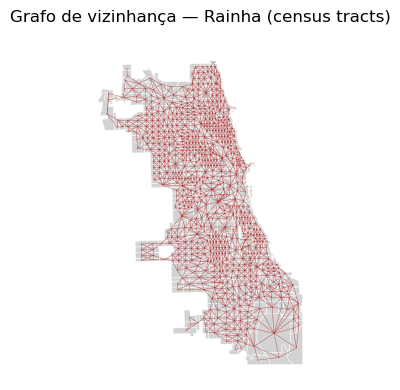

In [5]:
fig, ax = plt.subplots(figsize=(4, 4))
gdf.plot(ax=ax, facecolor='lightgray', edgecolor='white', linewidth=0.3)
wq1.plot(gdf, ax=ax,
             edge_kws=dict(color='firebrick', linewidth=0.25, alpha=0.5),
             node_kws=dict(marker=''))
ax.set_title('Grafo de vizinhança — Rainha (census tracts)')
ax.set_axis_off()
plt.tight_layout()
plt.show()


### Histograma do número de vizinhos

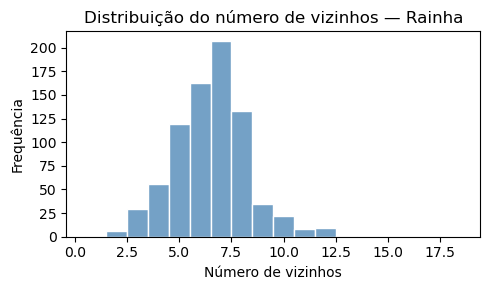

count    791.000000
mean       6.556258
std        1.837461
min        1.000000
25%        5.000000
50%        7.000000
75%        8.000000
max       18.000000
Name: n_vizinhos, dtype: float64


In [6]:
card = pd.Series(wq1.cardinalities, name='n_vizinhos')

fig, ax = plt.subplots(figsize=(5, 3))
sns.histplot(card, bins=range(int(card.min()), int(card.max()) + 2),
             discrete=True, color='steelblue', edgecolor='white', ax=ax)
ax.set_xlabel('Número de vizinhos')
ax.set_ylabel('Frequência')
ax.set_title('Distribuição do número de vizinhos — Rainha')
ax.yaxis.set_major_locator(matplotlib.ticker.MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

print(card.describe())

## 4. Specification search

Variável dependente: log da renda per capita (`ln_PerCap14`).  
Explicativas: % sem ensino médio (`EP_NOHSDP`), % pop. negra (`Blk14P`),
% pop. hispânica (`Hisp14P`) e tx. desemprego (`Unemp14`).

In [7]:
gdf['ln_PerCap14'] = np.log(gdf['PerCap14'])
y = gdf['ln_PerCap14']
x = gdf[['EP_NOHSDP', 'Blk14P', 'Hisp14P', 'Unemp14']]

gdf[['ln_PerCap14', 'PerCap14', 'EP_NOHSDP', 'Blk14P', 'Hisp14P', 'Unemp14']].describe()

,ln_PerCap14,PerCap14,EP_NOHSDP,Blk14P,Hisp14P,Unemp14
count,791.000000,791.000000,791.000000,791.000000,791.000000,791.000000
mean,10.042704,27956.975980,19.197977,37.208217,25.898609,15.569406
std,0.605515,19592.205294,13.577521,40.656771,29.417072,10.088934
min,8.031710,3077.000000,0.000000,0.000000,0.000000,0.600000
25%,9.594172,14679.000000,8.900000,2.700000,3.200000,7.900000
50%,9.962511,21216.000000,17.400000,11.600000,11.700000,13.000000
75%,10.429266,33835.500000,27.500000,90.800000,43.050000,20.700000
max,11.757776,127743.000000,65.400000,100.000000,99.100000,51.800000


### 4.1 MQO

In [8]:
# Atenção: spat_diag=True para obter os testes espaciais.
mqo = spreg.OLS(y, x, w=wq1, spat_diag=True, name_w='Queen 1')
print(mqo.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     Queen 1
Dependent Variable  : ln_PerCap14                Number of Observations:         791
Mean dependent var  :     10.0427                Number of Variables   :           5
S.D. dependent var  :      0.6055                Degrees of Freedom    :         786
R-squared           :      0.8257
Adjusted R-squared  :      0.8248
Sum squared residual:      50.477                F-statistic           :    931.0752
Sigma-square        :       0.064                Prob(F-statistic)     :  2.046e-296
S.E. of regression  :       0.253                Log likelihood        :     -34.051
Sigma-square ML     :       0.064                Akaike info criterion :      78.103
S.E of regression ML:      0.2526                Schwarz criterion     :     101.469

-----------------

### Interpretação — diagnósticos espaciais do MQO (STGE-Pre)

Seguimos a estratégia *specific-to-general pre-test* (STGE-Pre) de Anselin, Serenini e Amaral (2025). O primeiro passo **não** é o par clássico LM-lag / LM-erro, e sim o LM de $WX$.

**Resultado-chave:** o LM de $WX$ é significativo a 1%.  
Isso rejeita a hipótese de que não há efeito indireto dos vizinhos. Em outras palavras: há indicação de transbordamentos locais em $X$.

Estratégia STGE-Pre:

1. Como o LM-WX rejeitou, **não** seguimos a rotina clássica de Anselin (2005) (LM-lag vs. LM-erro).
2. Passamos à rotina de testes para o **Spatial Durbin** (Koley e Bera, 2024):
   - teste conjunto do SDM ($LM_{\rho\theta}$);
   - se significativo, olhar os robustos de $WX$ e de lag;
   - os dois robustos significativos $\rightarrow$ SDM;
   - só um significativo $\rightarrow$ fica aquela alternativa (SLX ou SAR);
   - nesta ramificação o **SEM não entra** como concorrente.



### 4.2 SLX

In [9]:
# O argumento slx_lags especifica o número de lags espaciais de X a serem incluídas no modelo.
slx = spreg.OLS(y, x, w=wq1, spat_diag=True, slx_lags=1, name_w='Queen 1')
print(slx.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES WITH SPATIALLY LAGGED X (SLX)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     Queen 1
Dependent Variable  : ln_PerCap14                Number of Observations:         791
Mean dependent var  :     10.0427                Number of Variables   :           9
S.D. dependent var  :      0.6055                Degrees of Freedom    :         782
R-squared           :      0.8423
Adjusted R-squared  :      0.8407
Sum squared residual:     45.6695                F-statistic           :    522.2145
Sigma-square        :       0.058                Prob(F-statistic)     :  1.266e-307
S.E. of regression  :       0.242                Log likelihood        :       5.533
Sigma-square ML     :       0.058                Akaike info criterion :       6.934
S.E of regression ML:      0.2403                Schwarz criterion     : 

Depois de incluir $WX$, os LM clássicos de lag e de erro continuam rejeitando ($p < 0{,}001$). Pela regra da aula, olhamos os **robustos**:

| Teste | p-valor | Leitura |
|-------|----------:|---------|
| LM-lag robusto | 0,036 | ainda há defasagem em $y$ |
| LM-erro robusto | 0,086 | SEM não se sustenta a 5% |

Nenhum teste robusto rejeita a $H_0$ a 1%, então podemos:
- Focar no com maior probabilidade de rejeição (menor p-valor)
- Focar no com pior consequência caso ignorado (viés de variável omitida $Wy$ vs. ineficiência omissão de erro espacial)

Seguindo a estratégia Anselin, Serenini e Amaral (2025), ambos caminhos apontam para acrescentar $Wy$: **estimar o SDM**.

### 4.3 SDM (lag + SLX, via `GM_Lag`)

In [10]:
sdm = spreg.GM_Lag(y, x, w=wq1, spat_diag=True, slx_lags=1, name_w='Queen 1')
print(sdm.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: SPATIAL TWO STAGE LEAST SQUARES WITH SLX (SPATIAL DURBIN MODEL)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     Queen 1
Dependent Variable  : ln_PerCap14                Number of Observations:         791
Mean dependent var  :     10.0427                Number of Variables   :          10
S.D. dependent var  :      0.6055                Degrees of Freedom    :         781
Pseudo R-squared    :      0.8994
Spatial Pseudo R-squared:  0.8389

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT         2.03485         1.69464         1.20076         0.22985
           EP_NOHSDP        -0.01323         0.00127       -1

O SDM estima $\rho$ em $Wy$ e os $\theta$ em $WX$. $\hat\rho = 0{,}816$ ($p < 0{,}001$).

**Anselin–Kelejian (1997)**

| Teste | DF | Estatística | $p$-valor |
|-------|---:|------------:|----------:|
| AK | 1 | $2{,}52$ | $0{,}112$ |

$H_0$: não resta autocorrelação espacial nos resíduos.

Não rejeitamos a 5%. Ou seja: uma vez incluídos $Wy$ e $WX$, não há evidência de um SARAR por cima. O AK cumpre o papel do LM-erro quando o modelo já é de lag.

**Hipótese de fator comum**

| Teste | DF | Estatística | $p$-valor |
|-------|---:|------------:|----------:|
| Common factor | 4 | $4{,}61$ | $0{,}329$ |

$H_0$: $\theta = -\rho\beta$ (4 restrições, uma por $X$).

Não rejeitamos. Pela aula, não rejeitar fator comum $\Rightarrow$ o SEM é suficiente: os $WX$ do SDM são compatíveis com o filtro de um processo no erro, não com transbordamentos substantivos à la SLX.

**Como ler os dois juntos**

- AK: o SDM controla toda dependência espacial do modelo: não podemos rejeijtar agora que resíduos sejam espacialmente aleatórios.
- Fator comum: não podemos rejeitar que $\theta = -\rho\beta$. Modelo simplifica para SEM.

Por isso o próximo modelo da prática é o **SEM** — não porque o AK tenha apontado erro *dentro* do SDM, mas porque o fator comum devolve a especificação para o erro.

### 4.4 SEM (erro espacial, via `GMM_Error`)

In [11]:
err = spreg.GMM_Error(y, x, w=wq1, name_w='Queen 1')
print(err.summary)

REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: GM SPATIALLY WEIGHTED LEAST SQUARES (HET)
------------------------------------------------------------------------------------
Data set            :     unknown
Weights matrix      :     Queen 1
Dependent Variable  : ln_PerCap14                Number of Observations:         791
Mean dependent var  :     10.0427                Number of Variables   :           5
S.D. dependent var  :      0.6055                Degrees of Freedom    :         786
Pseudo R-squared    :      0.8184
N. of iterations    :           1                Step1c computed       :          No

------------------------------------------------------------------------------------
            Variable     Coefficient       Std.Error     z-Statistic     Probability
------------------------------------------------------------------------------------
            CONSTANT        10.98533         0.05077       216.36412         0.00000
           EP_NOHSDP        -0.0

## Exercício

Usando a mesma base de Chicago (chicagoSDOH):

1. Utilizando uma matriz de pesos de k-vizinhos mais próximos (use k=7), encontre a melhor especificação para o modelo com as mesmas variáveis dependente e explicativas